<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="B Nazanin" size=7 color="#0099cc">
    تمرین سری 4 درس سیگنال ها و سیستم ها
</font>

</p>

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="B Nazanin" size=4>
    در این تمرین هدف یادگیری استفاده از مفاهیم سری فوریه و تبدیل فوریه است.
     حتما تمامی سلول ها را بعد از پایان کار اجرا کرده و نوت بوک را همراه با خروجی سلول ها ذخیره کنید. محل قرارگیری کدهای شما  با <code>Your Code #</code> مشخص شده است. به هیچ عنوان تغییری در سایر سلول ها ایجاد نکنید. و در نهایت این فایل نهایی را به صورت <code>stdNumber_name</code> نام کذاری کرده و در سامانه اپلود کنید. علاوه بر فایل نوت بوک، گزارش کار هم در فایل زیپ قرار دهید. فایل گزارش باید شامل نتایج کد شما باشد و توجه کنید که در گزارش کد خود را قرار ندهید.(گزارش حتما به صورت تایپی و با فرمت pdf باشد.)
</font>
</p>

In [41]:
import numpy as np
import matplotlib.pyplot as plt

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:large">
<font face="B Nazanin" size=10 color="#0099cc">
    پرسش اول:
    سری فوریه
</font>
</p>

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
در این بخش به شما دو سیگنال متناوب داده شده است:
</font>
</p>

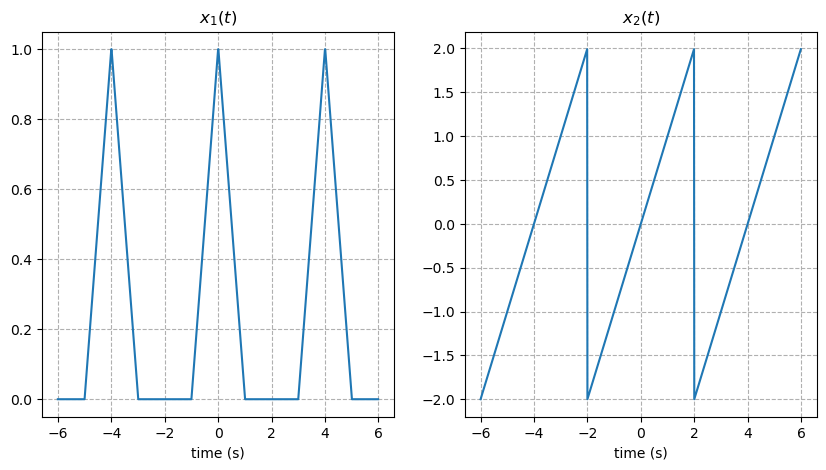

In [42]:
def generate_x1(step=0.01):
    samples = int(1/step)
    t = np.arange(-2, 2, step=step)
    y_t = np.zeros((4)*samples)
    for i in range(samples):
        y_t[samples+i+1] = t[samples+i+1]+1
        y_t[3*samples-i]= t[samples+i+1]+1
    t=np.append(t-4, np.append(t,t+4))
    y_t=np.append(y_t, np.append(y_t, y_t))
    return t,y_t


def generate_x2(step=0.01):
    samples = int(1/step)
    t = np.arange(-2, 2, step=step)
    y_t = np.zeros((4)*samples)
    for i in range(4*samples):
        y_t[i] = t[i]
    t=np.append(t-4, np.append(t,t+4))
    y_t=np.append(y_t, np.append(y_t, y_t))
    return t,y_t



t1, xt1 = generate_x1 ()
t2, xt2 = generate_x2 ()

plt.figure (figsize=(10,5))

plt.subplot (1,2,1)
plt.plot (t1, xt1)
plt.grid (ls='--')
plt.title ('$x_1 (t)$')
plt.xlabel ('time (s)')

plt.subplot (1,2,2)
plt.plot (t2, xt2)
plt.grid (ls='--')
plt.title ('$x_2 (t)$')
plt.xlabel ('time (s)')

plt.show ()

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
 با توجه به تعریف سری فوریه، سیگنال های x1 و x2 را
با تعداد هارمونیک های 1، 5، 10 و 20 تایی بازسازی و سپس رسم کنید.
با افزایش تعداد هارمونیک ها، چه تغییری در شکل سیگنال به وجود می آید؟ توضیح دهید.
</font>

</p>

$$x(t) = \sum_{k=-\infty}^{\infty}{a_{k}e^{jkw_{0}t}}, \quad w_{0} = \frac{2\pi}{T}$$
$$ a_{k} = \frac{1}{T} \int_{T}{x(t) e^{-jkw_{0} t}dt}, \quad w_{0} = \frac{2\pi}{T} $$


<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
(راهنمایی: در ویدیوی مربوط به سری و تبدیل فوریه، نحوه پیاده سازی آن توضیح داده شده است.)
</font>

</p>

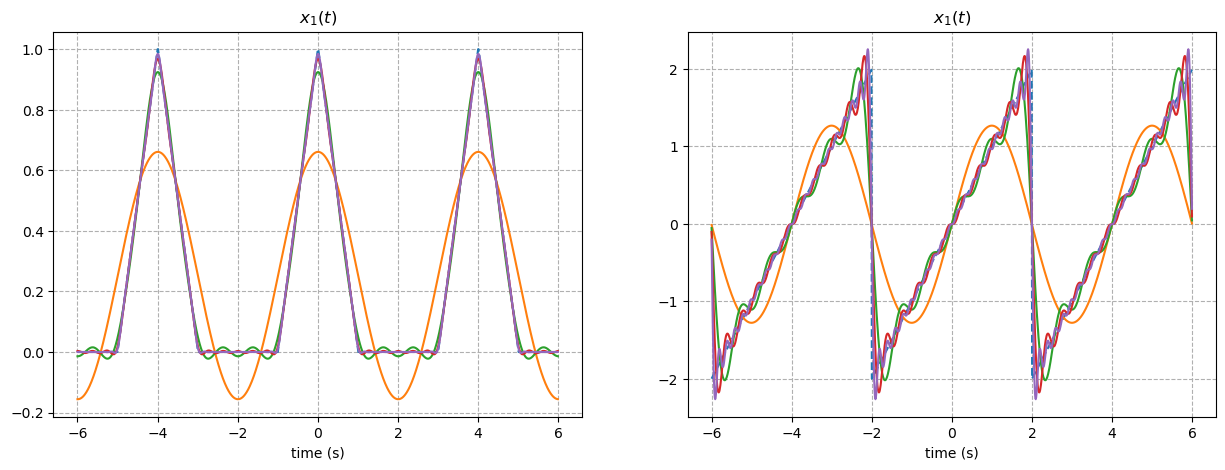

In [43]:
def filter(arr):
    cond1 = np.logical_and((arr.imag < 10e-5), (arr.imag > 0))
    cond2 = np.logical_and((arr.imag > -10e-5), (arr.imag < 0))
    cond3 = np.logical_or(cond1, cond2)
    arr = np.where(cond3, arr.real, arr)
    return arr
def calculate_ak(sig, time, harmonic_range=(-10, 10), T=None):
    h_r = np.arange(harmonic_range[0], harmonic_range[1] + 1, 1)
    n = np.full((h_r.shape[0], time.shape[0]), h_r.reshape(-1, 1))
    expression = sig * np.exp(-1j * n * 2* np.pi * time/T)
    a = (1 /(T)) * np.trapz(expression, time)
    a = filter(a)
    return a

def calculate_x_hat(a, time, harmonic_range=None, T=None, dispatch=False):
    a_inv = np.repeat(a.reshape(-1, 1), time.shape[0], axis=1)
    k = np.arange(harmonic_range[0], harmonic_range[1] + 1, 1)
    k = np.repeat(k.reshape(-1, 1), time.shape[0], axis=1)
    x = a_inv * np.exp(1j * k * time * 2 * np.pi / T)
    if dispatch == True:
        return x
    else:
        return filter(np.sum(x, axis=0))

ak1 = calculate_ak(xt1,t1,(-1,1),4)
x1_hat_1 = calculate_x_hat(ak1,t1,(-1,1),4)
h_r_1 = (-1,1)
h_r_1_range = np.arange(h_r_1[0], h_r_1[1] + 1, 1)

ak5 = calculate_ak(xt1,t1,(-5,5),4)
x1_hat_5 = calculate_x_hat(ak5,t1,(-5,5),4)
h_r_5 = (-5,5)
h_r_5_range = np.arange(h_r_5[0], h_r_5[1] + 1, 1)

ak10 = calculate_ak(xt1,t1,(-10,10),4)
x1_hat_10 = calculate_x_hat(ak10,t1,(-10,10),4)
h_r_10 = (-10,10)
h_r_10_range = np.arange(h_r_10[0], h_r_10[1] + 1, 1)


ak20 = calculate_ak(xt1,t1,(-20,20),4)
x1_hat_20 = calculate_x_hat(ak20,t1,(-20,20),4)
h_r_20 = (-20,20)
h_r_20_range = np.arange(h_r_20[0], h_r_20[1] + 1, 1)

ak12 = calculate_ak(xt2,t2,(-1,1),4)
x2_hat_1 = calculate_x_hat(ak12,t2,(-1,1),4)
h_r_12 = (-1,1)
h_r_12_range = np.arange(h_r_12[0], h_r_12[1] + 1, 1)

ak52 = calculate_ak(xt2,t2,(-5,5),4)
x2_hat_5 = calculate_x_hat(ak52,t2,(-5,5),4)
h_r_52 = (-5,5)
h_r_52_range = np.arange(h_r_52[0], h_r_52[1] + 1, 1)

ak102 = calculate_ak(xt2,t2,(-10,10),4)
x2_hat_10 = calculate_x_hat(ak102,t2,(-10,10),4)
h_r_102 = (-10,10)
h_r_102_range = np.arange(h_r_102[0], h_r_102[1] + 1, 1)


ak202 = calculate_ak(xt2,t2,(-20,20),4)
x2_hat_20 = calculate_x_hat(ak202,t2,(-20,20),4)
h_r_202 = (-20,20)
h_r_202_range = np.arange(h_r_202[0], h_r_202[1] + 1, 1)

# TODO: Plot the signals:
plt.figure (figsize=(15,5))

plt.subplot (1,2,1)

plt.title ('$x_1 (t)$')
plt.xlabel ('time (s)')

plt.plot (t1, xt1, linestyle='--')
plt.plot (t1, x1_hat_1.real/3) # x1_hat_1
plt.plot (t1, x1_hat_5.real/3) # x1_hat_5
plt.plot (t1, x1_hat_10.real/3) # x1_hat_10
plt.plot (t1, x1_hat_20.real/3) # x1_hat_20
plt.grid (ls='--')

plt.subplot (1,2,2)

plt.title ('$x_1 (t)$')
plt.xlabel ('time (s)')

plt.plot (t2, xt2, linestyle='--')
plt.plot (t2, x2_hat_1.real/3) # x1_hat_1
plt.plot (t2, x2_hat_5.real/3) # x1_hat_5
plt.plot (t2, x2_hat_10.real/3) # x1_hat_10
plt.plot (t2, x2_hat_20.real/3) # x1_hat_20
plt.grid (ls='--')

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
حال برای هر سیگنال، ضرایب
<code>ak</code>
را رسم کنید. (با توجه به این که ضرایب اعداد مختلط هستند، بخش اندازه و فاز را جداگانه رسم کنید.)
</font>

</p>

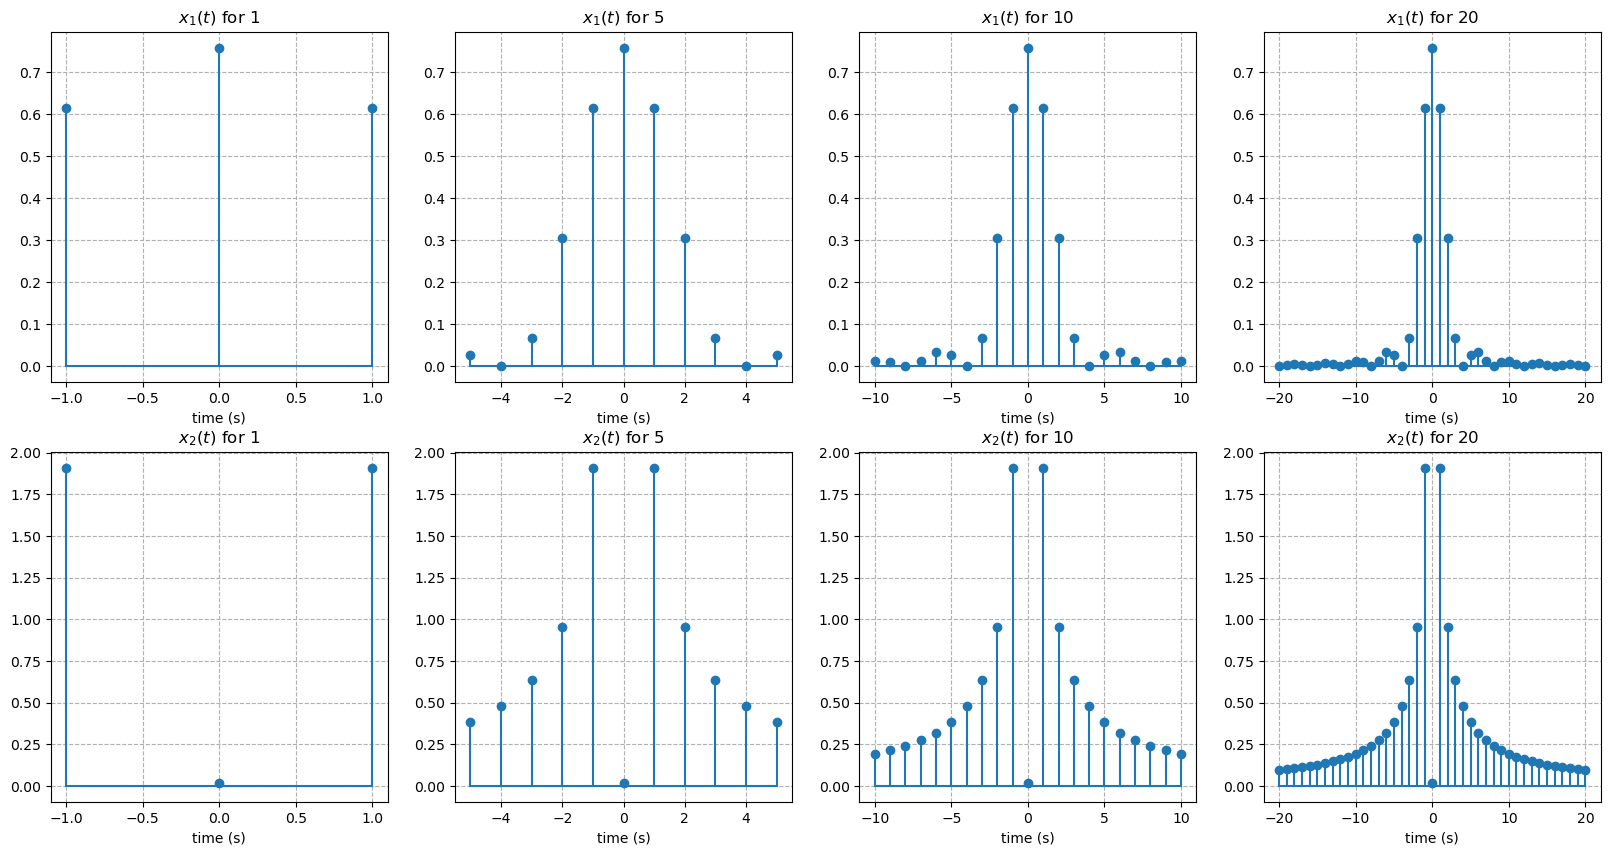

In [44]:
plt.figure (figsize=(20,10))

plt.subplot (2,4,1)

plt.title ('$x_1 (t)$ for 1')
plt.xlabel ('time (s)')
plt.stem (h_r_1_range, np.abs(ak1), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,2)

plt.title ('$x_1 (t)$ for 5')
plt.xlabel ('time (s)')
plt.stem (h_r_5_range, np.abs(ak5), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,3)

plt.title ('$x_1 (t)$ for 10')
plt.xlabel ('time (s)')
plt.stem (h_r_10_range, np.abs(ak10), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,4)

plt.title ('$x_1 (t)$ for 20')
plt.xlabel ('time (s)')
plt.stem (h_r_20_range, np.abs(ak20), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,5)

plt.title ('$x_2 (t)$ for 1')
plt.xlabel ('time (s)')
plt.stem (h_r_12_range, np.abs(ak12), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,6)

plt.title ('$x_2 (t)$ for 5')
plt.xlabel ('time (s)')
plt.stem (h_r_52_range, np.abs(ak52), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,7)

plt.title ('$x_2 (t)$ for 10')
plt.xlabel ('time (s)')
plt.stem (h_r_102_range, np.abs(ak102), basefmt='')
plt.grid (ls='--')

plt.subplot (2,4,8)

plt.title ('$x_2 (t)$ for 20')
plt.xlabel ('time (s)')
plt.stem (h_r_202_range, np.abs(ak202), basefmt='')
plt.grid (ls='--')

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:large">
<font face="B Nazanin" size=10 color="#0099cc">
    پرسش دوم:
</font>
</p>


<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
در این بخش میخواهیم ضرایب سری فوریه یک سیگنال صوت واقعی را رسم کنیم!
برای این کار، نیاز به وارد کردن کلاس زیر از کتابخانه سای پای داریم:
</font>

</p>

In [45]:
from scipy.io import wavfile

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
با استفاده از تابع زیر، میخواهیم فایل را به آرایه نامپای تبدیل کنیم. پس، برای درستی انجام کار، توصیه میشود که حتما تمام پوشه تمرین را از حالت فشرده خارج کنید.
</font>

</p>

In [46]:
sample_rate, data = wavfile.read ('sound.wav')

sample_step = 1. / sample_rate
length = data.shape [0] / sample_rate

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
فایل صوت در حدود 3 ثانیه است که با توجه به نرخ نمونه برداری بالای آن، آرایه ای بسیار طولانی است. در نتیجه، تنها به 1000 نمونه اول آن میپردازیم.
</font>

</p>

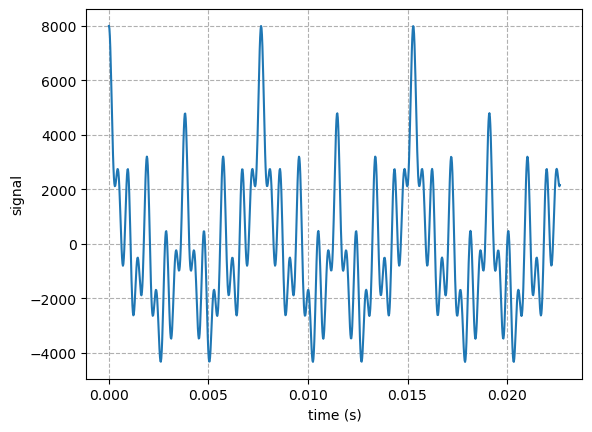

In [47]:
t = (np.arange (0, length, step=sample_step)) [:1000]
x_t = data [:1000]

plt.plot (t, x_t)
plt.grid (ls='--')
plt.ylabel ('signal')
plt.xlabel ('time (s)')
plt.show ()

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
دیده میشود که سیگنال صوت متناوب است! (دوره تناوب 150 است.)
ضرایب سری فوریه آن را رسم کنید.
</font>

</p>

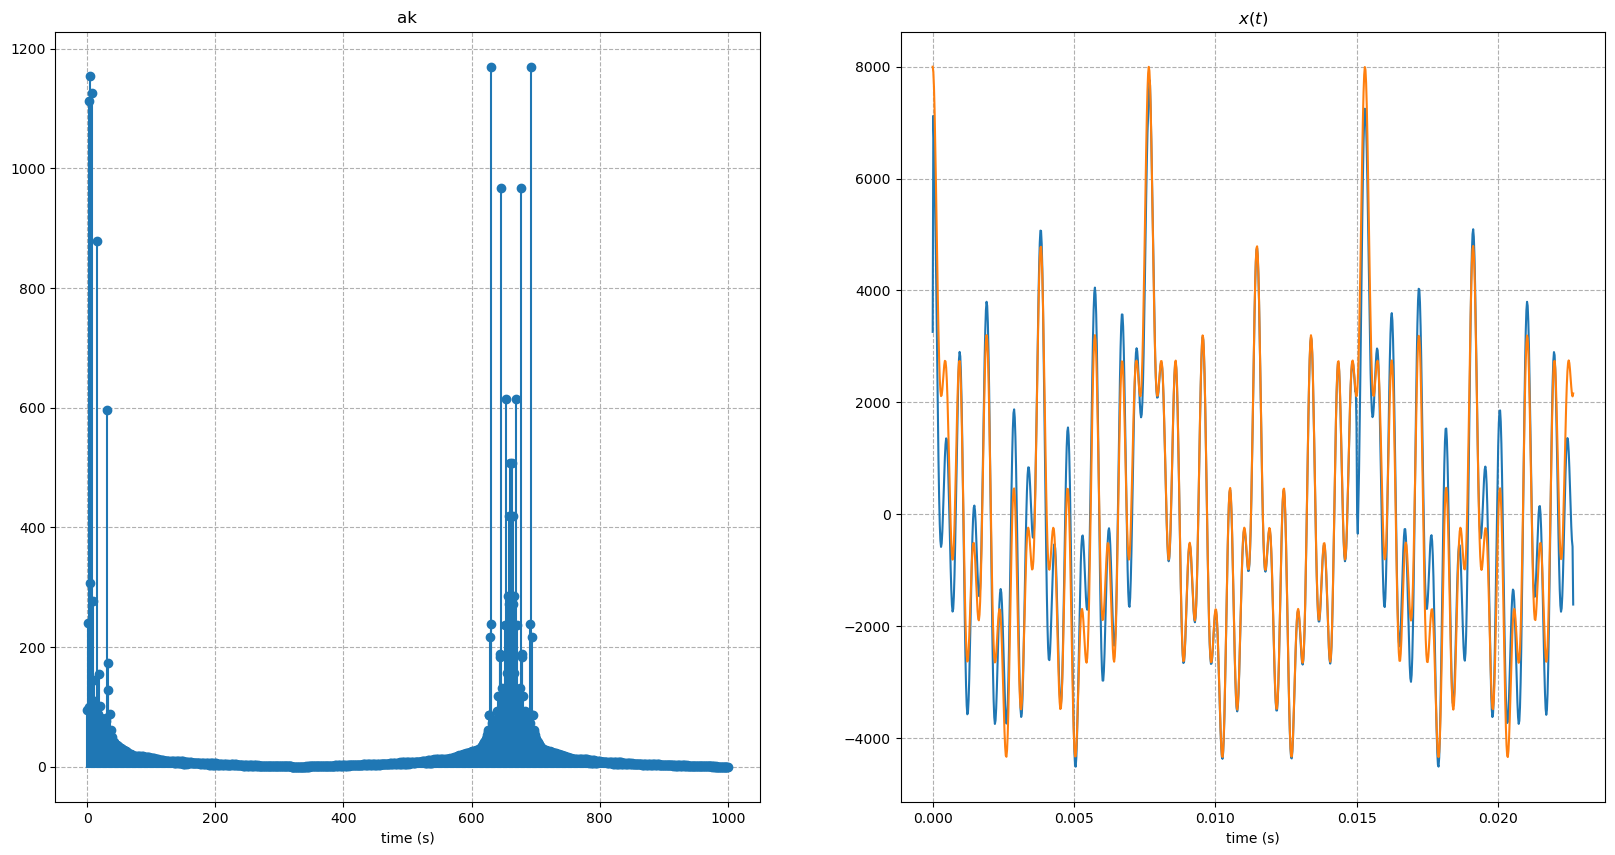

In [48]:
ak1 = calculate_ak(x_t,t,(0,1000),0.015)
x1_hat_1 = calculate_x_hat(ak1,t,(0,1000),0.015)
h_r_1 = (0,1000)
h_r_1_range = np.arange(h_r_1[0], h_r_1[1] + 1, 1)

plt.figure (figsize=(20,10))

plt.subplot (1,2,1)

plt.title ('ak')
plt.xlabel ('time (s)')
plt.stem (h_r_1_range, np.abs(ak1), basefmt='')
plt.grid (ls='--')

plt.subplot (1,2,2)

plt.title ('$x (t)$')
plt.xlabel ('time (s)')
plt.plot (t, x1_hat_1 /1.5)
plt.plot (t, x_t)
plt.grid (ls='--')

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:large">
<font face="B Nazanin" size=10 color="#0099cc">
    پرسش سوم:
    تبدیل فوریه
</font>
</p>


<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
سیگنال صوت داده در پرسش قبل را در نظر بگیرید. با استفاده از دستورات داخلی نامپای یا سایپای، سیگنال را در حوزه فرکانسی رسم کنید. با توجه به این که اعداد در حوزه فرکانس مختلط هستند، اندازه و فاز آن را در شکل های جداگانه رسم کنید. (حتما توضیحات داخل ویدیو را در نظر بگیرید.)
</font>

</p>

c:\ProgramData\anaconda3\lib\site-packages\matplotlib\cbook\__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


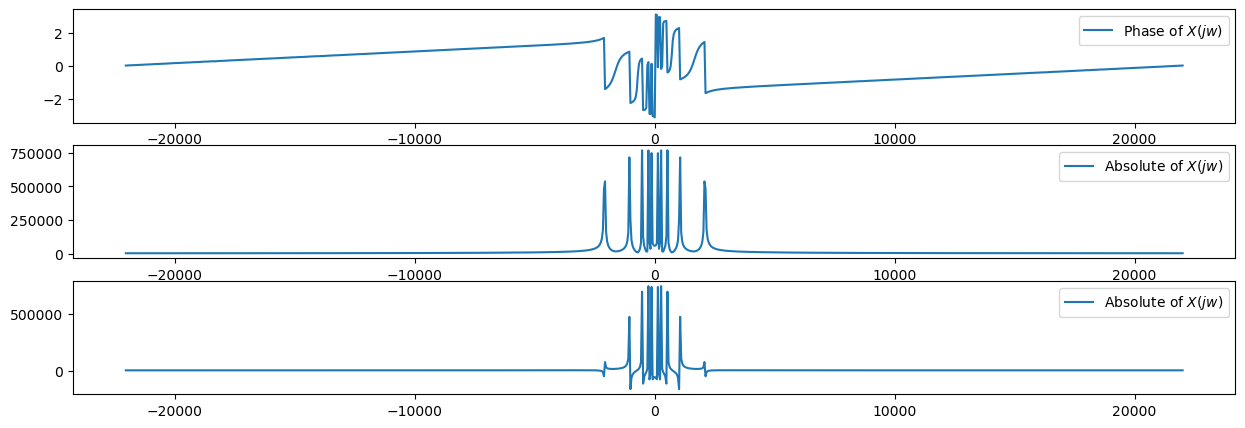

In [62]:
from scipy import fft

FT = fft.fftshift(fft.fft(x_t))
f = fft.fftshift(fft.fftfreq(t.shape[0], (t[1] - t[0]) ))

fig, ax = plt.subplots(3, 1, figsize=(15, 5))

ax[0].plot(f, np.angle(FT), label="Phase of $X(jw)$")
ax[0].legend()

ax[1].plot(f, np.abs(FT), label="Absolute of $X(jw)$")
ax[1].legend()

ax[2].plot(f, FT, label="Absolute of $X(jw)$")
ax[2].legend()

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
در این قسمت قصد داریم برخی از فرکانس های سیگنال را حذف کنیم!
</font>

</p>

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
در ابتدا، تمامی فرکانس ها به جز دو فرکانس اول را صفر کنید و سپس، تمامی فرکانس ها به جر دو فرکانس آخر را صفر کنید. برای این کار، از
array slicing
استفاده کنید.
</font>

</p>

<code>
freq [-(len (freq) - 2):] = 0

freq [:len (freq) - 2] = 0
</code>

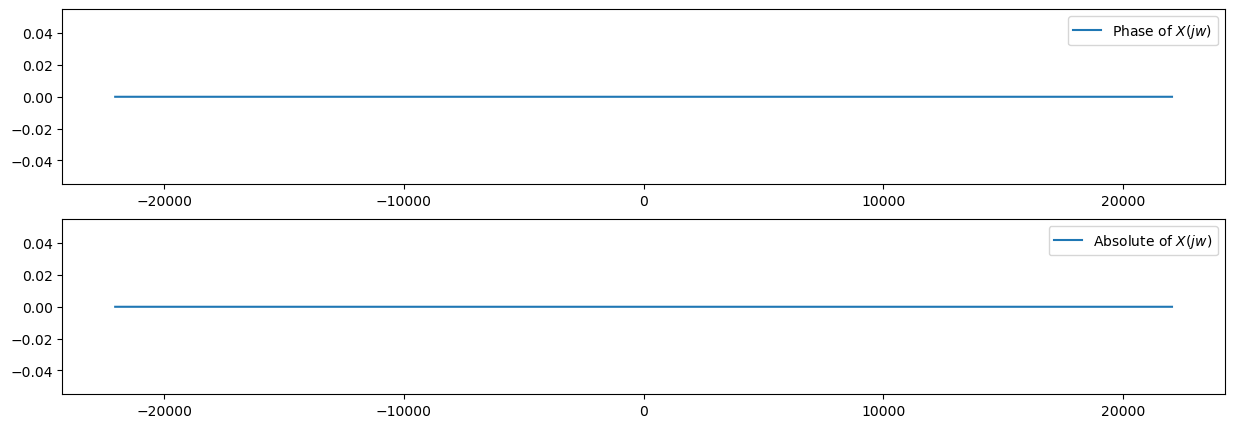

In [85]:
from scipy import fft
FT = fft.fftshift(fft.fft(x_t))
f = fft.fftshift(fft.fftfreq(t.shape[0], (t[1] - t[0]) ))
FT1 = FT
FT2 = FT
FT1[-(len (FT1) - 1000):] = 0
FT2 [:len (FT2) - 1000] = 0
fig, ax = plt.subplots(2, 1, figsize=(15, 5))

ax[0].plot(f, np.angle(FT), label="Phase of $X(jw)$")
ax[0].legend()

ax[1].plot(f, np.abs(FT), label="Absolute of $X(jw)$")
ax[1].legend()

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:large">
<font face="B Nazanin" size=10 color="#0099cc">
    پرسش چهارم: (اختیاری)
    
</font>
</p>



<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:B Nazanin;font-size:medium">

<font face="B Nazanin" size=5>
این بخش از تمرین اختیاری است و صرفا برای گوش دادن به نتیجه سیگنال های تولید شده در بخش قبلی است. در صورتی که بخواهید، حتی میتوانید بخش های مختلف از فرکانس ها را حذف یا اضافه کنید تا نتایج را با هم مقایسه کنید.
</font>

</p>

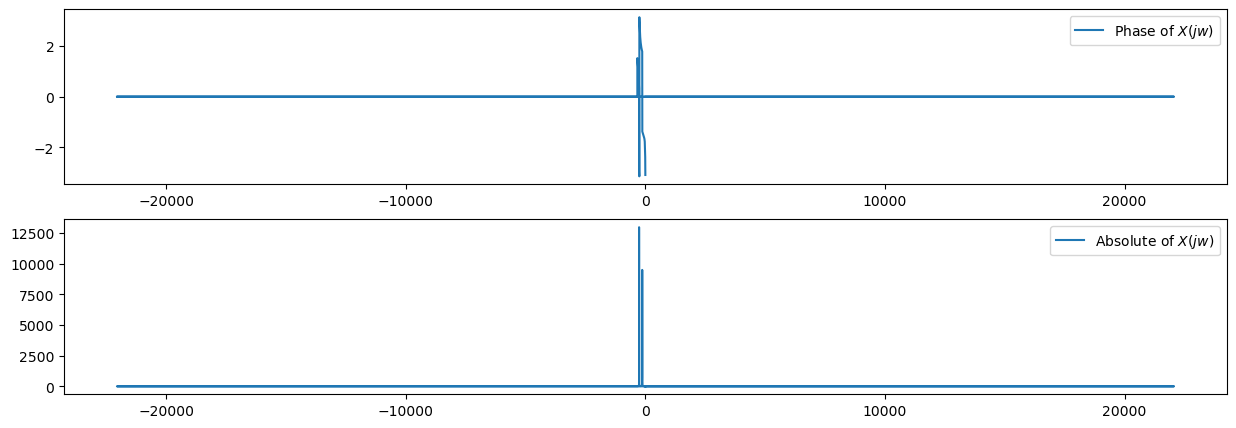

In [81]:
from scipy.fft import fft, ifft, fftfreq

t = (np.arange (0, length, step=sample_step))
max_element = max (data)
x_t = data / max_element

f = fftfreq(t.shape[0], (t[1] - t[0]) )

x_freq = fft (x_t)
x_freq [:len (x_freq) - 1000] = 0
new_x_t = ifft (x_freq) * sample_rate

fig, ax = plt.subplots(2, 1, figsize=(15, 5))

ax[0].plot(f, np.angle(x_freq), label="Phase of $X(jw)$")
ax[0].legend()

ax[1].plot(f, np.abs(x_freq), label="Absolute of $X(jw)$")
ax[1].legend()

wavfile.write ('result_1.wav', sample_rate, new_x_t.real.astype (np.float32) * 3000)


x_freq = fft (x_t)
x_freq [-(len (x_freq) - 1000):] = 0
new_x_t = ifft (x_freq) * sample_rate
wavfile.write ('result_2.wav', sample_rate, new_x_t.real.astype (np.float32) * 3000)